In [1]:

# Step 1: Import the required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings("ignore")

# Set the visualization style
sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:

import pandas as pd

url = "https://huggingface.co/datasets/DElmazi/Student_Performance/resolve/main/student-mat.csv"

df = pd.read_csv(url, sep=";")

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Number of rows: 395
Number of columns: 33


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [4]:

# Step 3: Explore the dataset

print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    o

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


In [8]:

# STEP 4: Create the at_risk column

df["at_risk"] = (df["G3"] < 10).astype(int)

print("at_risk column created successfully!")

# Display the columns to verify
print(df.columns.tolist())

# Display sample data
display(df[["G3", "at_risk"]].head())

# Count students in each category
print("\nStudent performance categories:")
print(df["at_risk"].value_counts())

print("\nPercentage of students flagged:")
print(round(df["at_risk"].mean() * 100, 2), "%")

KeyError: 'at_risk'

In [7]:

print(df.columns.tolist())

['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']


Dataset shape: (395, 34)
G3 exists: True
at_risk exists: True
   G3  at_risk
0   6        1
1   6        1
2  10        0
3  15        0
4  10        0


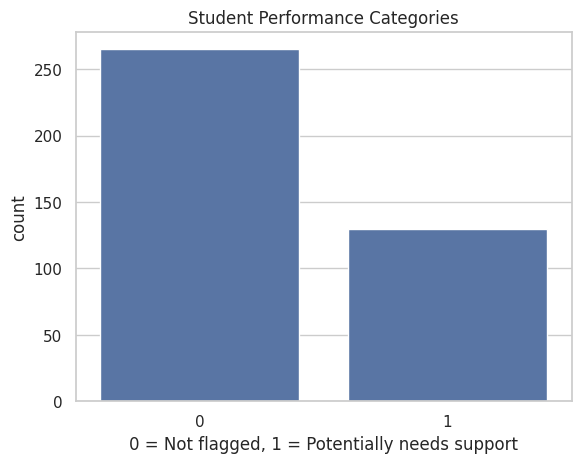

In [10]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Reload the dataset
url = "https://huggingface.co/datasets/DElmazi/Student_Performance/resolve/main/student-mat.csv"
df = pd.read_csv(url, sep=";")

# Create the target column immediately
df["at_risk"] = (df["G3"] < 10).astype(int)

# Verify everything
print("Dataset shape:", df.shape)
print("G3 exists:", "G3" in df.columns)
print("at_risk exists:", "at_risk" in df.columns)
print(df[["G3", "at_risk"]].head())

# Plot
sns.countplot(data=df, x="at_risk")
plt.title("Student Performance Categories")
plt.xlabel("0 = Not flagged, 1 = Potentially needs support")
plt.show()

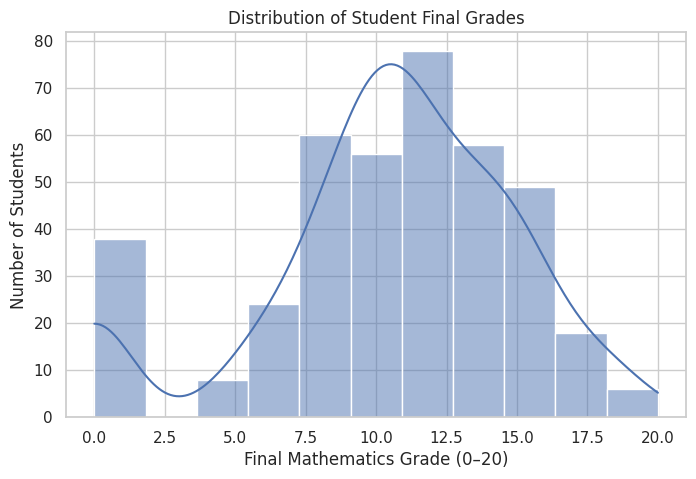

In [13]:

# Step 5: Visualize final mathematics grades

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="G3",
    bins=11,
    kde=True
)

plt.title("Distribution of Student Final Grades")
plt.xlabel("Final Mathematics Grade (0–20)")
plt.ylabel("Number of Students")

plt.show()

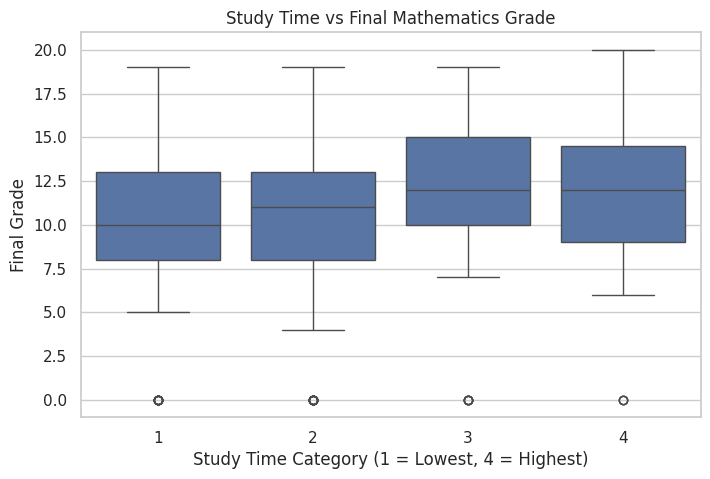

In [15]:

# Compare study time and final grades

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="studytime",
    y="G3"
)

plt.title("Study Time vs Final Mathematics Grade")
plt.xlabel("Study Time Category (1 = Lowest, 4 = Highest)")
plt.ylabel("Final Grade")

plt.show()

In [18]:

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Create target column
df["at_risk"] = (df["G3"] < 10).astype(int)

# Select features and target
X = df[["studytime", "failures", "absences", "G1", "G2"]]
y = df["at_risk"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Train model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)
model.fit(X_train, y_train)

# Predict and evaluate
y_pred = model.predict(X_test)

print("Model Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Model Accuracy: 91.14 %

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.92      0.93        53
           1       0.85      0.88      0.87        26

    accuracy                           0.91        79
   macro avg       0.90      0.90      0.90        79
weighted avg       0.91      0.91      0.91        79


Confusion Matrix:
[[49  4]
 [ 3 23]]


In [19]:

# Step 7: Predict for a sample student

sample_student = pd.DataFrame([{
    "studytime": 2,
    "failures": 0,
    "absences": 4,
    "G1": 12,
    "G2": 13
}])

prediction = model.predict(sample_student)[0]
probability = model.predict_proba(sample_student)[0][1]

if prediction == 1:
    print("Prediction: Student may need additional academic support.")
else:
    print("Prediction: Student is not flagged as at risk.")

print("Estimated risk probability:", round(probability * 100, 2), "%")

Prediction: Student is not flagged as at risk.
Estimated risk probability: 0.0 %
